# GSE269084

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2025-12-06
> - Modified: 2026-01-05

# 1. Experimental Design

> RNA transcripts regulate G-quadruplex landscapes through G-loop formation
> - Karolinska Institutet
> - Illumina Nextseq 2000, PE75
> - Koichi Sato et al. ,RNA transcripts regulate G-quadruplex landscapes through G-loop formation.Science388,1225-1231(2025).DOI:10.1126/science.adr0493.

| Sample | Organism | Cell | Tissue | Treatment | Replicate | Library | Genome |
| - | - | - | - | - | - | - | - |
| Dhx36-Fancj WT | Mus musculus | mESC | Embryonic stem cell | Wild type | rep1~3 (G4), rep1~2 (Rloop) | CUT&Tag | mm10 |
| Dhx36 KO | Mus musculus | mESC | Embryonic stem cell | Dhx36 KO | rep1~3 (G4), rep1~2 (Rloop) | CUT&Tag | mm10 |
| Fancj KO | Mus musculus | mESC | Embryonic stem cell | Brip1 (Fancj) KO | rep1~3 (G4), rep1~2 (Rloop) | CUT&Tag | mm10 |
| Dhx36-Fancj dKO | Mus musculus | mESC | Embryonic stem cell | Dhx36-Fancj dKO | rep1~3 (G4), rep1~2 (Rloop) | CUT&Tag | mm10 |
| Ercc1 WT | Mus musculus | mESC | Embryonic stem cell | Wild type | rep1~2 (G4, Rloop) | CUT&Tag | mm10 |
| Ercc1 KO | Mus musculus | mESC | Embryonic stem cell | Ercc1 KO | rep1~2 (G4, Rloop) | CUT&Tag | mm10 |

In [2]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [1]:
data_dir <- "~/dataset_1/bulk/CUTTag_Mm_mESC_G4_GSE269084/CUTtag/02_output"

# 2. Evaluate Library Quality

In [8]:
genotypes <- c(
    "Dhx36-Fancj WT", "Dhx36 KO", "Fancj KO", "Dhx36-Fancj dKO", 
    "Ercc1 WT", "Ercc1 KO")

## 1). Mapping Statistics

| Sample | Total Fragments | Mapping Fragments | Mapping Rate | Unique Mapping Fragments | Unique Mapping Rate | PCR Duplicates Rate | Number Of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - |
| mEF_DNBSEQ_rep1 | 56043293 | 52887991 | 94.37% | 46685962 | 83.30% | 19.92% | 174784 | 54.08% |

## 2). Fragment Size Distribution

In [4]:
file.path(data_dir, "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |> head()

,Size,Occurrences,Sample
,<int>,<int>,<chr>
1,34,1,mESC_Dhx36-Fancj_dKO_rep1_G4
2,37,1,mESC_Dhx36-Fancj_dKO_rep1_G4
3,38,2,mESC_Dhx36-Fancj_dKO_rep1_G4
4,39,2,mESC_Dhx36-Fancj_dKO_rep1_G4
5,40,7,mESC_Dhx36-Fancj_dKO_rep1_G4
6,41,16,mESC_Dhx36-Fancj_dKO_rep1_G4


In [9]:
fragment_size <- file.path(data_dir, "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    separate(
        Sample, into = c("Cell", "Gene", "Type", "Replicate", "Antibody"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell), 
        Genotype = paste(Gene, Type, sep = " ") |> factor(levels = genotypes),
        Replicate = factor(Replicate), 
        Antibody = factor(Antibody, levels = c("G4", "Rloop"))) |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

In [12]:
result <- fragment_size |>
    group_by(Sample) |>
    summarise(
        mean_trim_1pct = mean(
            Size, trim = 0.01, na.rm = TRUE) |> round(digits = 0),
        median_trim_1pct = {
            lower <- quantile(Size, 0.01, na.rm = TRUE)
            upper <- quantile(Size, 0.99, na.rm = TRUE)
            median(Size[Size >= lower & Size <= upper], na.rm = TRUE)
        } |> round(digits = 0)
    )

message("Mean of fragment size: ", round(mean(result$mean_trim_1pct), 0))
message("Median of fragment size: ", round(mean(result$median_trim_1pct), 0))

Mean of fragment size: 365

Median of fragment size: 351



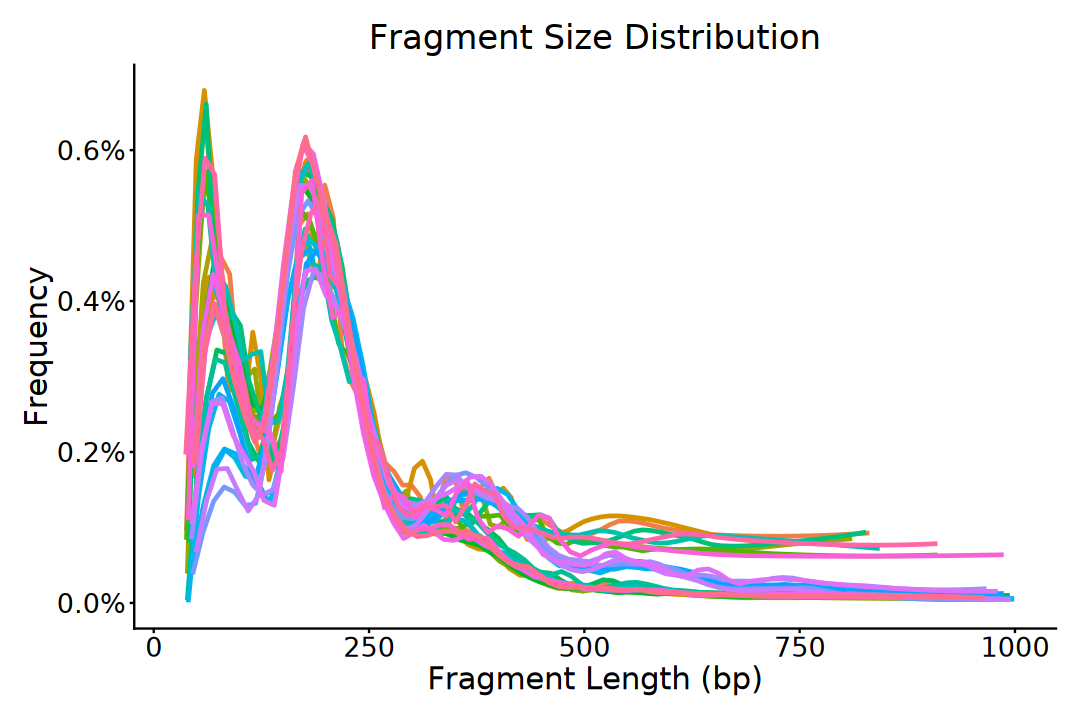

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(fragment_size, aes(x = Size, y = Freq, color = Sample)) +
    # geom_line(linewidth = 1) + 
    # geom_area(alpha = 0.4, position = "identity") +
    geom_smooth(
        formula = y ~ x, method = "loess", na.rm = TRUE,
        se = FALSE, span = 0.1, linewidth = 1) +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    labs(
        title = "Fragment Size Distribution", color = "Sample",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16),
        legend.position = "none",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16))

## 4). MACS2 Cutoff Analysis

In [21]:
cutoff_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_cutoff_analysis.txt$", full.names = TRUE) |>
    set_names(~ sub("(.*)_cutoff_analysis\\.txt$", "\\1", basename(.x)))

In [22]:
cutoff_dat <- cutoff_files |>
    map_df(~ {
        df <- read.table(.x, header = TRUE)
        df$sample <- sub("(.*)_cutoff_analysis\\.txt$", "\\1", basename(.x))
        return(df)
    })

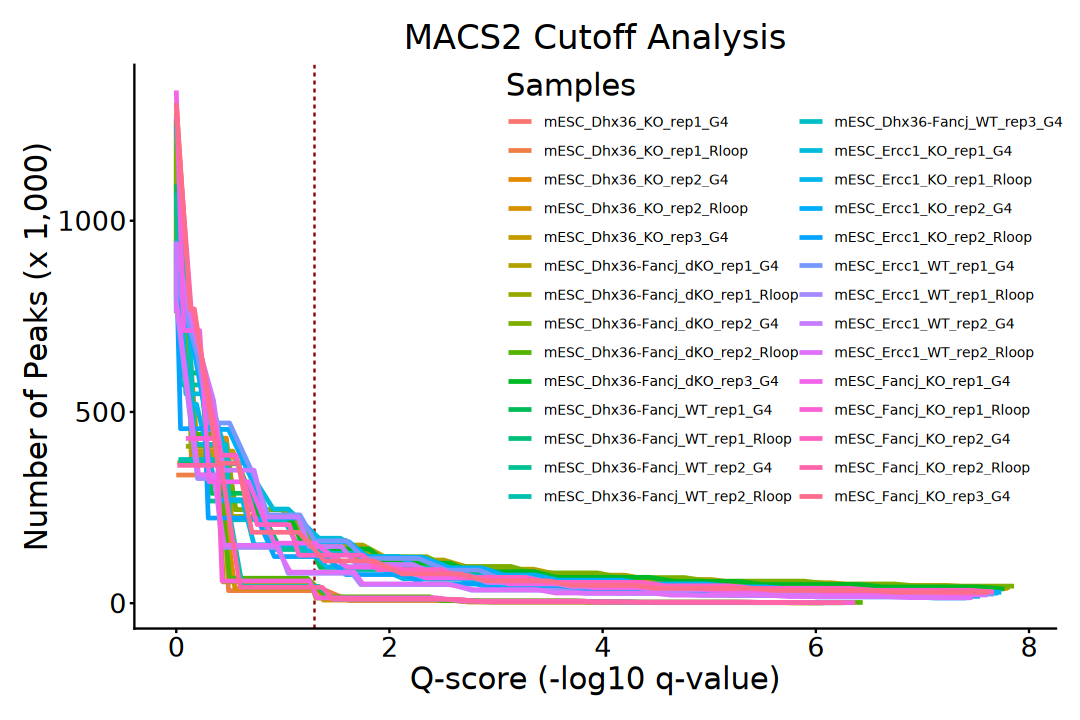

In [28]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(cutoff_dat, aes(
    x = qscore, y = npeaks, color = sample, group = sample)) +
    geom_vline(
        xintercept = -log10(0.05), linewidth = 0.5,
        linetype = "dashed", color = "darkred") +
    geom_line(linewidth = 1) +
    # scale_x_reverse() + 
    scale_y_continuous(labels = function(x) x / 1000) + 
    labs(title = "MACS2 Cutoff Analysis", color = "Samples",
         x = "Q-score (-log10 q-value)",
         y = "Number of Peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16),
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.6),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 8))

## 5). Sample Correlation

In [29]:
bins_mat <- file.path(data_dir, "09_count", "bins_10kb.counts.tsv") |> 
    read.table(header = TRUE, sep = "\t", comment.char = "") |>
    dplyr::rename(chr = X.chr) |>
    mutate(pos = paste0(chr, ":", start, "-", end)) |>
    select(-chr, -start, -end) |>
    column_to_rownames("pos")

In [30]:
cor_mat <- cor(bins_mat, method = "spearman")

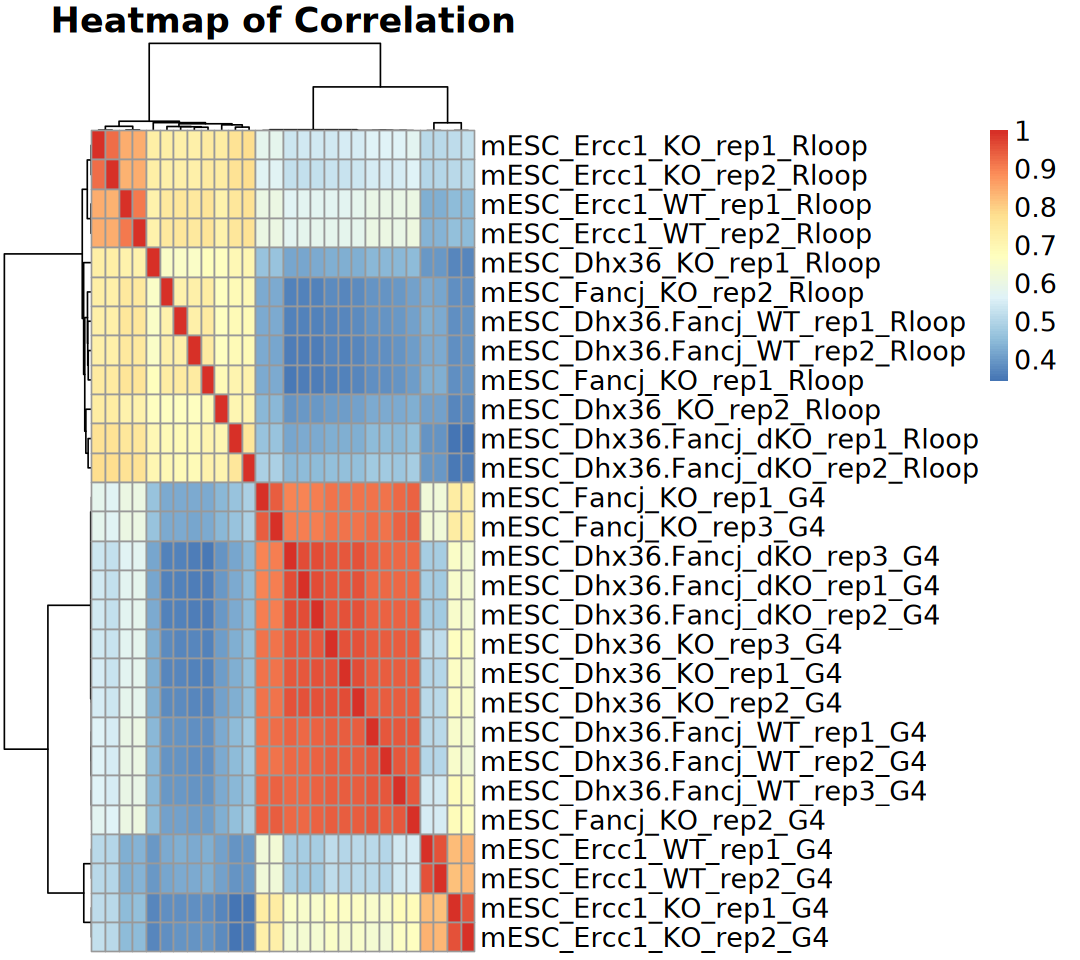

In [32]:
options(repr.plot.width = 9, repr.plot.height = 8)
pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

# 4. Levels: Signals

In [38]:
# load reference gene anntotion
gtf <- import("~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf") |> 
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

## 1). Import bigwig

In [33]:
signals_files <- file.path(data_dir, "07_bigwig") |>
    list.files(pattern = "\\.bw$") |>
    set_names(~ sub("(.*)\\.bw$", "\\1", .x))

# signals_files <- signals_files[!grepl("bin1", signals_files)]

paste(names(signals_files), signals_files, sep = ": ") |> cat(sep = "\n")

mESC_Dhx36_KO_rep1_G4: mESC_Dhx36_KO_rep1_G4.bw
mESC_Dhx36_KO_rep1_Rloop: mESC_Dhx36_KO_rep1_Rloop.bw
mESC_Dhx36_KO_rep2_G4: mESC_Dhx36_KO_rep2_G4.bw
mESC_Dhx36_KO_rep2_Rloop: mESC_Dhx36_KO_rep2_Rloop.bw
mESC_Dhx36_KO_rep3_G4: mESC_Dhx36_KO_rep3_G4.bw
mESC_Dhx36-Fancj_dKO_rep1_G4: mESC_Dhx36-Fancj_dKO_rep1_G4.bw
mESC_Dhx36-Fancj_dKO_rep1_Rloop: mESC_Dhx36-Fancj_dKO_rep1_Rloop.bw
mESC_Dhx36-Fancj_dKO_rep2_G4: mESC_Dhx36-Fancj_dKO_rep2_G4.bw
mESC_Dhx36-Fancj_dKO_rep2_Rloop: mESC_Dhx36-Fancj_dKO_rep2_Rloop.bw
mESC_Dhx36-Fancj_dKO_rep3_G4: mESC_Dhx36-Fancj_dKO_rep3_G4.bw
mESC_Dhx36-Fancj_WT_rep1_G4: mESC_Dhx36-Fancj_WT_rep1_G4.bw
mESC_Dhx36-Fancj_WT_rep1_Rloop: mESC_Dhx36-Fancj_WT_rep1_Rloop.bw
mESC_Dhx36-Fancj_WT_rep2_G4: mESC_Dhx36-Fancj_WT_rep2_G4.bw
mESC_Dhx36-Fancj_WT_rep2_Rloop: mESC_Dhx36-Fancj_WT_rep2_Rloop.bw
mESC_Dhx36-Fancj_WT_rep3_G4: mESC_Dhx36-Fancj_WT_rep3_G4.bw
mESC_Ercc1_KO_rep1_G4: mESC_Ercc1_KO_rep1_G4.bw
mESC_Ercc1_KO_rep1_Rloop: mESC_Ercc1_KO_rep1_Rloop.bw
mESC_Ercc1_K

In [34]:
read_bigwig <- function(file, sample, path) {
    import.bw(file.path(path, file)) |>
        BRGenomics::tidyChromosomes(
            keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)
}

In [35]:
signals_list <- imap(
    signals_files, read_bigwig, 
    path = file.path(data_dir, "07_bigwig"))

In [36]:
signals_list[1]

$mESC_Dhx36_KO_rep1_G4
GRanges object with 27289491 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3003400      * |   0.00000
         [2]     chr1   3003401-3003410      * |   4.15424
         [3]     chr1   3003411-3003430      * |   8.30849
         [4]     chr1   3003431-3003440      * |  12.46270
         [5]     chr1   3003441-3003470      * |  16.61700
         ...      ...               ...    ... .       ...
  [27289487]     chrY 90829671-90829690      * |  16.61700
  [27289488]     chrY 90829691-90829700      * |  12.46270
  [27289489]     chrY 90829701-90829720      * |   8.30849
  [27289490]     chrY 90829721-90829730      * |   4.15424
  [27289491]     chrY 90829731-91744698      * |   0.00000
  -------
  seqinfo: 21 sequences from an unspecified genome


## 2). Metagene Profile

### a). deepTools

### b). EnrichedHeatmap

In [37]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [39]:
GENES <- subset(
    gtf, 
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [40]:
mat_gene_List <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "coverage", extend = 2000, w = 50, smooth = TRUE, 
    background = 0, keep = c(0, 0.99), target_ratio = 0.4)

In [43]:
cat(names(signals_files), sep = "\n")

mESC_Dhx36_KO_rep1_G4
mESC_Dhx36_KO_rep1_Rloop
mESC_Dhx36_KO_rep2_G4
mESC_Dhx36_KO_rep2_Rloop
mESC_Dhx36_KO_rep3_G4
mESC_Dhx36-Fancj_dKO_rep1_G4
mESC_Dhx36-Fancj_dKO_rep1_Rloop
mESC_Dhx36-Fancj_dKO_rep2_G4
mESC_Dhx36-Fancj_dKO_rep2_Rloop
mESC_Dhx36-Fancj_dKO_rep3_G4
mESC_Dhx36-Fancj_WT_rep1_G4
mESC_Dhx36-Fancj_WT_rep1_Rloop
mESC_Dhx36-Fancj_WT_rep2_G4
mESC_Dhx36-Fancj_WT_rep2_Rloop
mESC_Dhx36-Fancj_WT_rep3_G4
mESC_Ercc1_KO_rep1_G4
mESC_Ercc1_KO_rep1_Rloop
mESC_Ercc1_KO_rep2_G4
mESC_Ercc1_KO_rep2_Rloop
mESC_Ercc1_WT_rep1_G4
mESC_Ercc1_WT_rep1_Rloop
mESC_Ercc1_WT_rep2_G4
mESC_Ercc1_WT_rep2_Rloop
mESC_Fancj_KO_rep1_G4
mESC_Fancj_KO_rep1_Rloop
mESC_Fancj_KO_rep2_G4
mESC_Fancj_KO_rep2_Rloop
mESC_Fancj_KO_rep3_G4


In [45]:
sample_info <- data.frame(
    name = names(signals_list)[c(11,13,15,1,3,5,24,26,28,6,8,10)], 
    idx = c(11,13,15,1,3,5,24,26,28,6,8,10))

In [50]:
col_fun <- circlize::colorRamp2(c(0, 10, 50), c("#F7F7F7", "#FFA500", "#B2182B"))

lgd_signal <- Legend(col_fun = col_fun, title = "ATAC")

In [51]:
top_anno_fun <- function() {
    HeatmapAnnotation(
        lines = anno_enriched(
            gp = gpar(lwd = 2), ylim = c(1, 50)),
        height = unit(4, "cm"),
        show_legend = FALSE)}

In [52]:
ht_list <- NULL
for (i in seq_len(nrow(sample_info))) {
    ht_list <- ht_list + EnrichedHeatmap(
        mat_gene_List[[ sample_info$idx[i] ]], name = sample_info$name[i], 
        column_title = sample_info$name[i], col = col_fun, 
        use_raster = TRUE, show_heatmap_legend = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        top_annotation = top_anno_fun())
}

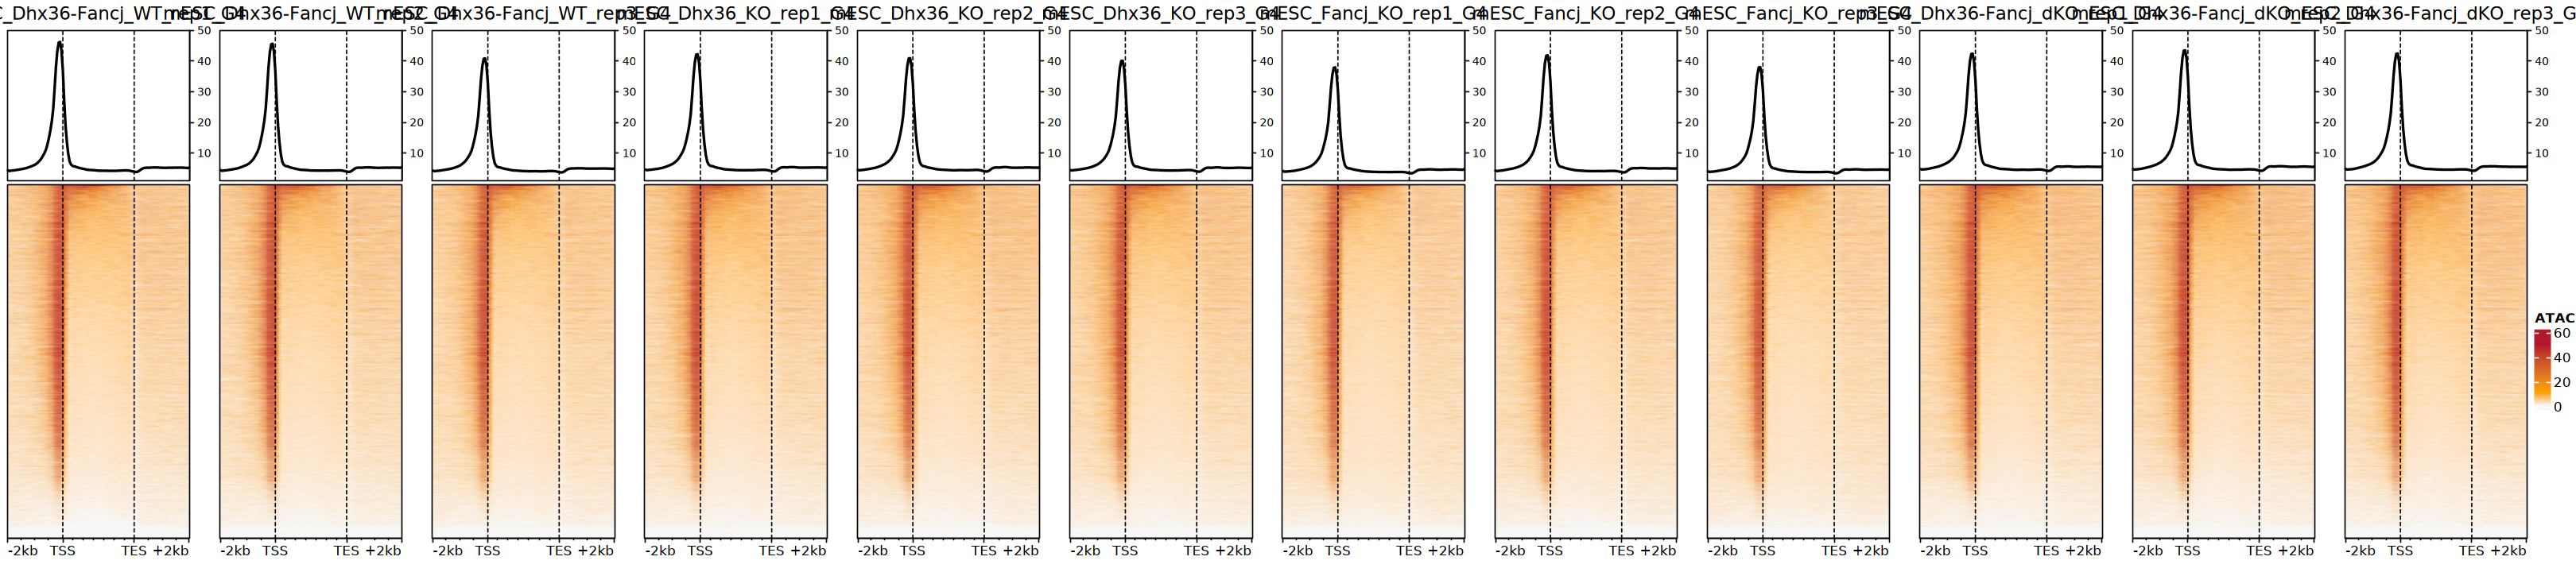

In [53]:
options(repr.plot.width = 27, repr.plot.height = 6)

draw(
    ht_list, 
    annotation_legend_list = list(lgd_signal), 
    ht_gap = unit(c(rep(8, nrow(sample_info))), "mm"))

In [54]:
profiles_list <- lapply(mat_gene_List, colMeans, na.rm = TRUE)

In [55]:
pos_levels <- c(sprintf("u%d", 1:40), sprintf("t%d", 1:53), sprintf("d%d", 1:40))

profiles_df <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    rownames_to_column("Position") |> 
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    separate(
        Sample, into = c("Cell", "Gene", "Type", "Replicate", "Antibody"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell), 
        Genotype = paste(Gene, Type, sep = " ") |> factor(levels = genotypes),
        Replicate = factor(Replicate), 
        Antibody = factor(Antibody, levels = c("G4", "Rloop")))

In [56]:
head(profiles_df)

Position,Sample,Cell,Gene,Type,Replicate,Antibody,Signal,Genotype
<chr>,<chr>,<fct>,<chr>,<chr>,<fct>,<fct>,<dbl>,<fct>
u1,mESC_Dhx36_KO_rep1_G4,mESC,Dhx36,KO,rep1,G4,4.579978,Dhx36 KO
u1,mESC_Dhx36_KO_rep1_Rloop,mESC,Dhx36,KO,rep1,Rloop,3.161062,Dhx36 KO
u1,mESC_Dhx36_KO_rep2_G4,mESC,Dhx36,KO,rep2,G4,4.519390,Dhx36 KO
u1,mESC_Dhx36_KO_rep2_Rloop,mESC,Dhx36,KO,rep2,Rloop,2.933008,Dhx36 KO
u1,mESC_Dhx36_KO_rep3_G4,mESC,Dhx36,KO,rep3,G4,4.441684,Dhx36 KO
u1,mESC_Dhx36-Fancj_dKO_rep1_G4,mESC,Dhx36-Fancj,dKO,rep1,G4,4.763268,Dhx36-Fancj dKO


## 3). IGV snapshot

In [ ]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(RColorBrewer))

In [ ]:
target_region <- "chr5:142889739-142922391"
genome = "mm10"

colors_palette <- colorRampPalette(brewer.pal(8, "Set2"))(length(signals_list))

In [ ]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(pos = V1, chr = V2, start = as.numeric(V3), 
              end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr5:142889739-142922391,chr5,142889739,142922391


In [ ]:
suppressPackageStartupMessages(library(AnnotationHub))

In [ ]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

In [ ]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

In [ ]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 14, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [ ]:
signal_tracks <- imap(signals_list, ~ {
    i <- which(names(signals_list) == .y)
    DataTrack(
        range = .x, name = .y, type = "histogram", 
        chromosome = target_region$chr, genome = genome, 
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = colors_palette[i], 
        fill.histogram = colors_palette[i])
})

In [ ]:
grtrack <- GeneRegionTrack(
    txdb, chromosome = target_region$chr, start = target_region$start, end = target_region$end,
    genome = genome, transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 20, cex.title = 1, fontsize.group = 16,
    name = "Gene", col = "grey", fill = "orange", rotation.title = 0,
    fontcolor.group = "black", stacking = "squish")

gene_info <- filter(gtf, type == "gene")
ranges(grtrack)$symbol <- gene_info$gene_name[match(ranges(grtrack)$gene, gene_info$gene_id)]

In [ ]:
options(repr.plot.width = 18, repr.plot.height = 12)
plotTracks(
    trackList = c(plot_list, signal_tracks, grtrack), 
    chromosome = target_region$chr, from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 3, rep(2.5, length(signals_list)), 2), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 0.8, just.group = "right",
    extend.left = 0, ylim = c(0, 800), yTicksAt = c(800))

## 4). Ideogram

In [ ]:
suppressPackageStartupMessages(library(RIdeogram))

In [ ]:
chromSize <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/mm10.chrom.sizes", 
    col.names = c("chrom", "chromSize"), header = FALSE, sep = "\t")

In [ ]:
# cytoBand <- read.table(
#     "~/reference/Mus_musculus/mm10/ucsc/cytoBand.txt", 
#     col.names = c("chrom", "chromStart", "chromEnd", "name", "gieStain"), 
#     header = FALSE, sep = "\t")

In [ ]:
# gap <- read.table(
#     "~/reference/Mus_musculus/mm10/ucsc/gap.txt", 
#     col.names = c("bin", "chrom", "chromStart", "chromEnd",
#                   "ix", "n", "size", "type", "bridge"), 
#     header = FALSE, sep = "\t")

In [ ]:
karyotype <- chromSize |> 
    mutate(Chr = chrom, Start = 0, End = chromSize) |>
    select(Chr, Start, End) |>
    filter(Chr %in% standard.chr)

In [ ]:
chr_sizes <- chromSize$chromSize
names(chr_sizes) <- chromSize$chrom

In [ ]:
bins <- tileGenome(seqlengths = chr_sizes, tilewidth = 1e6, 
                   cut.last.tile.in.chrom = TRUE)

In [ ]:
gene_density <- data.frame(
    Chr = seqnames(bins), Start = start(bins), End = end(bins), 
    Value = countOverlaps(bins, filter(gtf, type == "gene")))

In [ ]:
atac_density <- data.frame(
    Chr = seqnames(bins), Start = start(bins), End = end(bins), 
    Value = countOverlaps(bins, peaks_list$mESC_HiSeq_rep1), 
    Color = "fc8d62")

In [ ]:
output_ideogram <- file.path(data_dir, "01_stats", "chromosome.svg")

ideogram(karyotype = karyotype, overlaid = gene_density, 
         label = atac_density, label_type = "polygon",
         width = 170, output = output_ideogram)

# convertSVG(svg = output_ideogram,
#            file = file.path(data_dir, "01_stats", "chromosome.png"),
#            device = "png", width = 9, height = 6, dpi = 300)